# Wine Clustering: Finding Wine Styles without Labels

A wine shop gets lab measurements for 178 wines (alcohol, acidity, phenols, colour …), but nobody wrote down what *kind* of wine each one is. Here I try to sort them into styles from the numbers alone, check how stable those styles are, describe each one in plain words, and only at the very end open the hidden answer key (the grape variety) to see how close I got.

**Data** → [Wine Dataset for Clustering](https://www.kaggle.com/datasets/harrywang/wine-dataset-for-clustering) · 178 wines × 13 lab measurements · the same wines as the UCI wine data (3 grape varieties, hidden here)

<!-- app-highlight -->
## Highlight: Wine style finder app

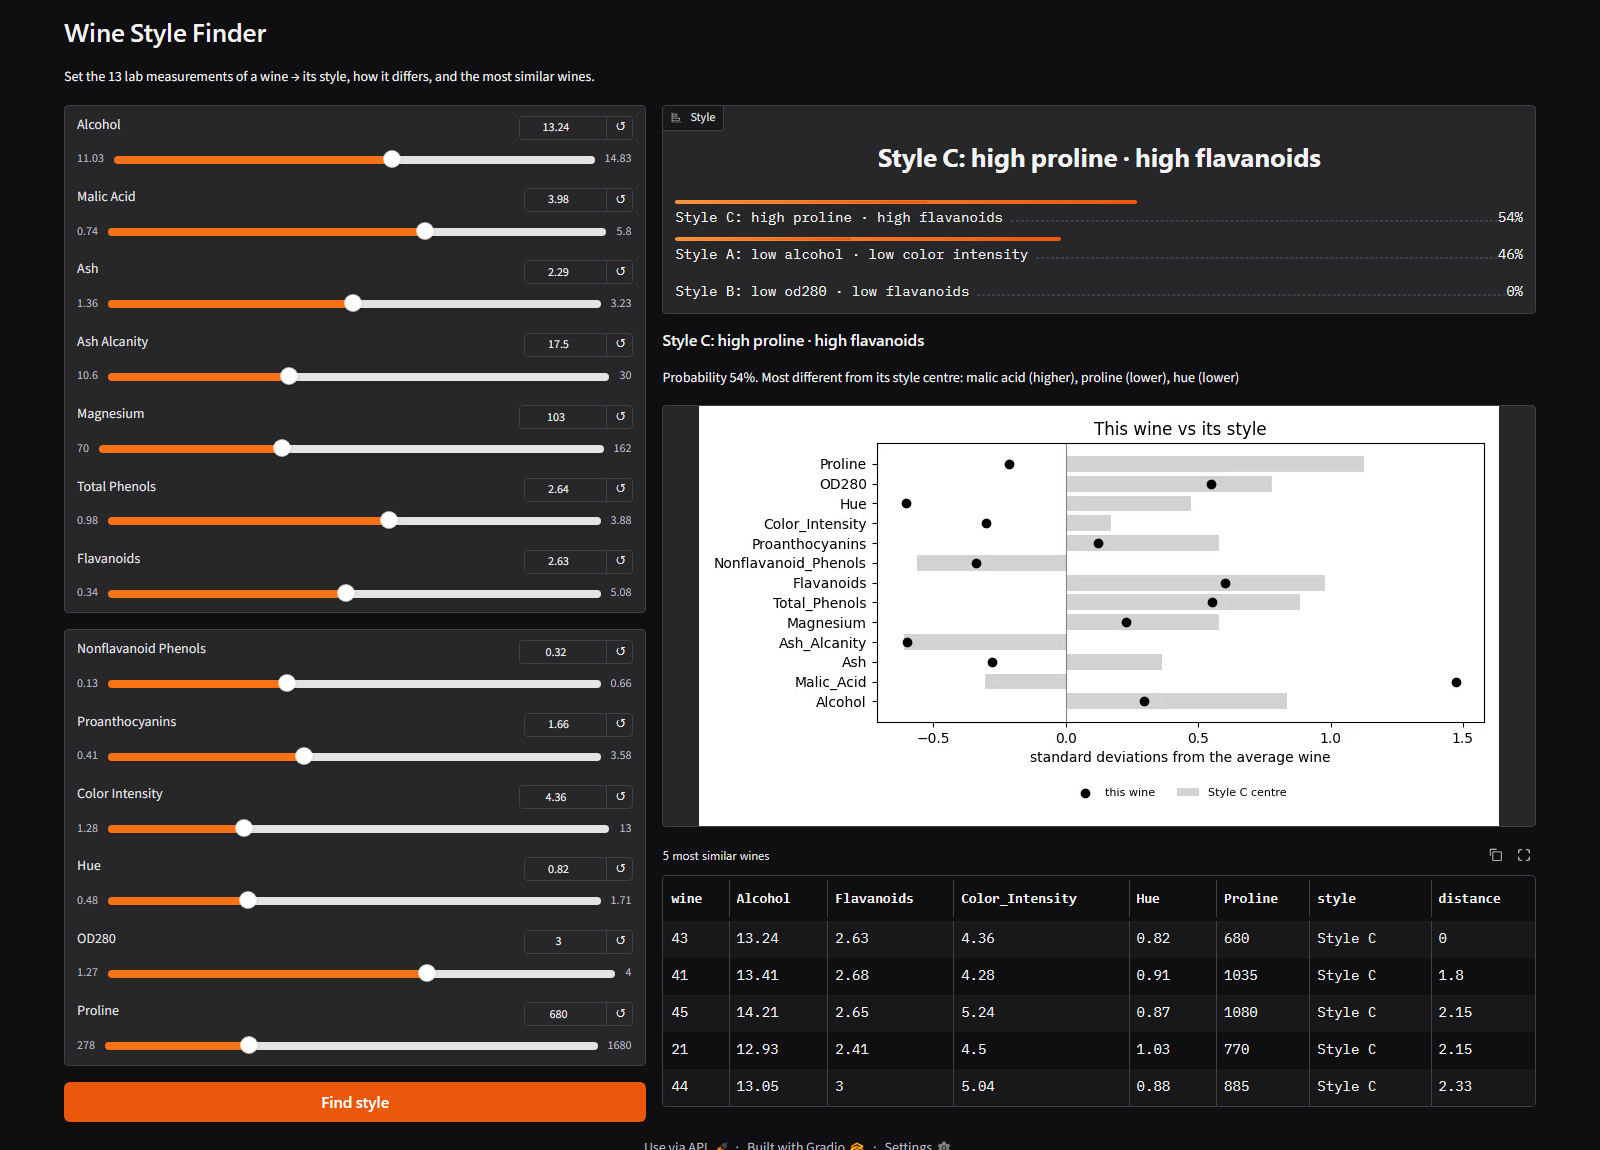

Enter a wine's lab measurements → its style probabilities, how it differs from the style centre, the 5 most similar wines, and a warning for unusual wines.

- **GitHub** → [ml-clustering-wine-kmeans-gmm](https://github.com/Pisit-Janthawee/ml-clustering-wine-kmeans-gmm) · full code, `app.py` and a README with all results
- **Run it** → `LAUNCH_APP = True` in the settings cell gives a temporary public link on Kaggle, or `pip install -r requirements.txt` → `python app.py` from the repo

<!-- objective -->
## Aim and objectives

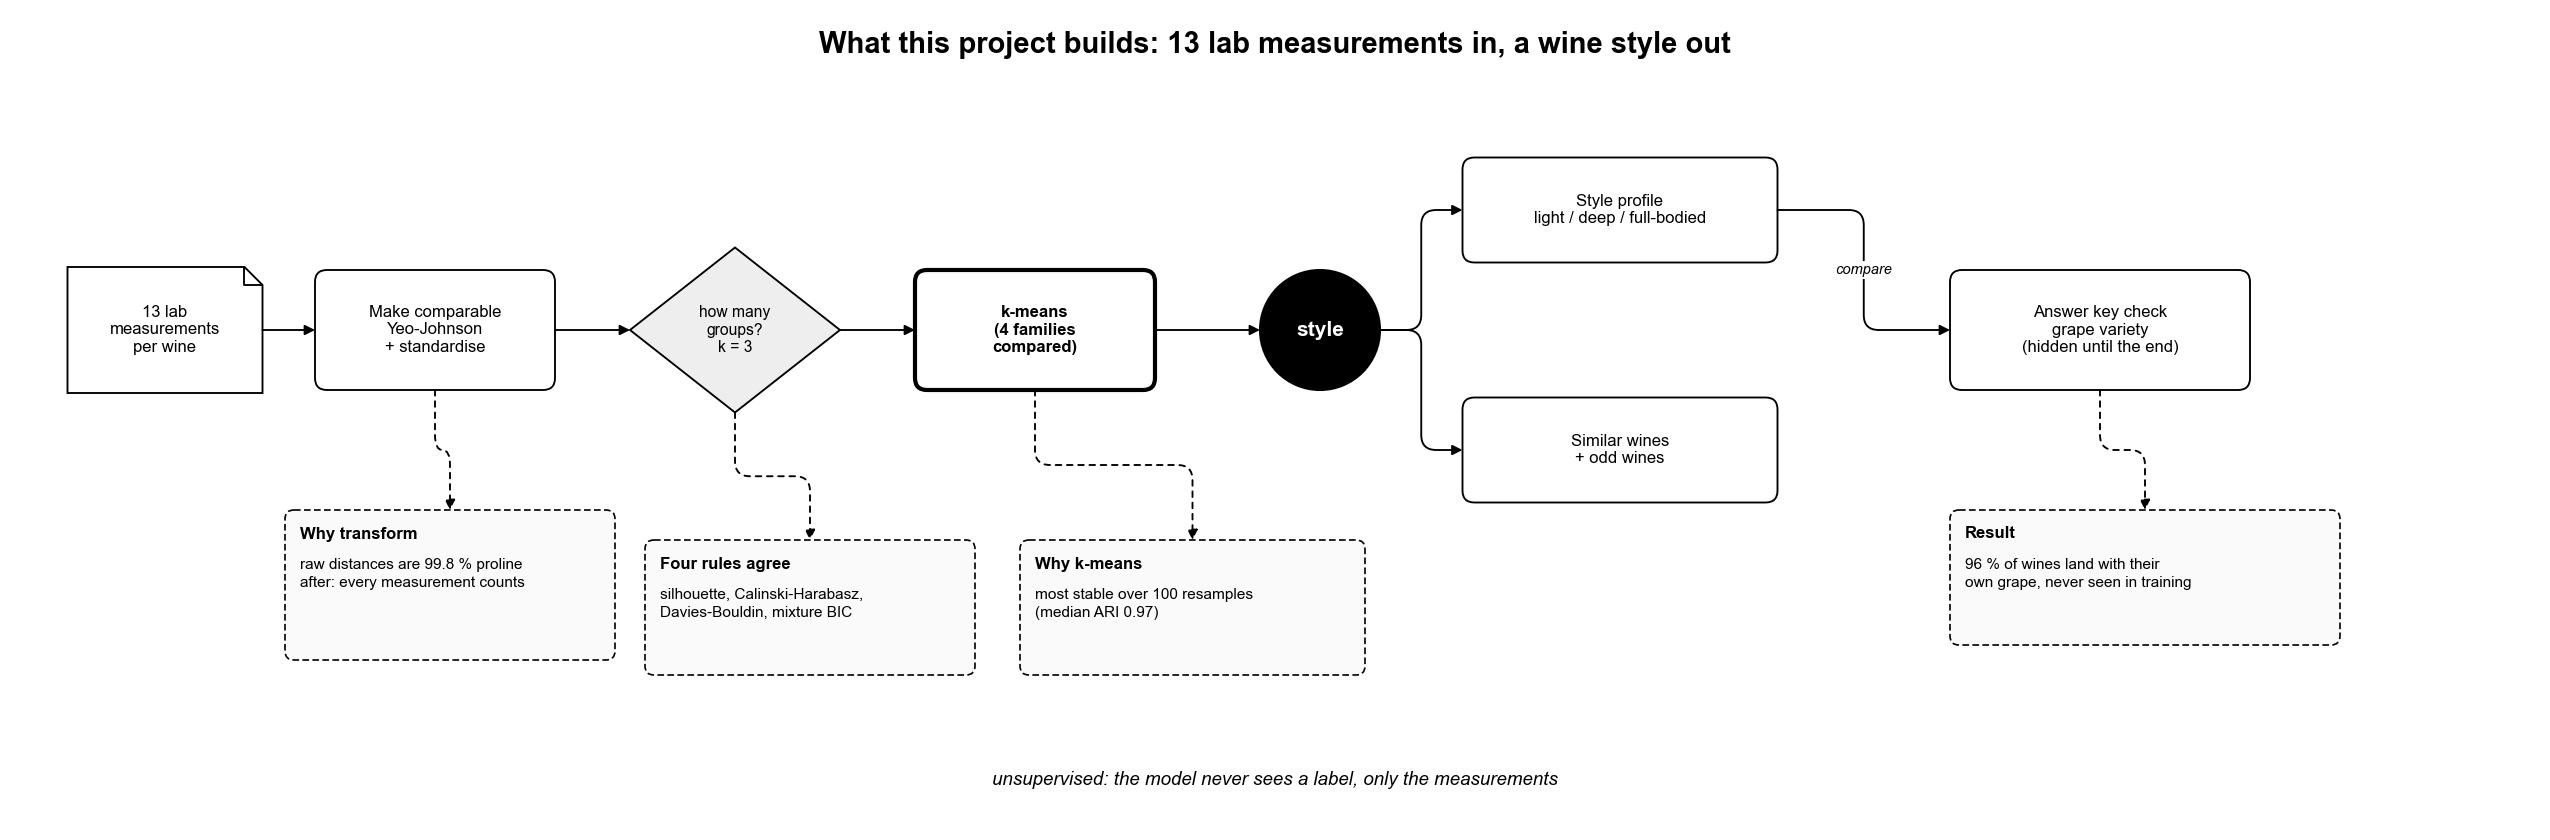

**Aim** → sort 178 wines into styles from their lab chemistry alone, check that the styles are stable, describe each one in plain words, and only then compare them with the real grape varieties.

**Objectives**
1. Find out which measurements need fixing before distances mean anything
2. Decide how many natural groups there are
3. Compare four families of clustering and check how stable their groups are
4. Describe each group in words a wine seller can use
5. Check the groups against the hidden grape varieties

**Where it could help** → a shop or distributor often has lab sheets for its wines but no agreed "style" labels, so shelves, menus and "if you liked this" suggestions are guesswork. Groups built from the chemistry give shelf and menu categories, "similar wines" suggestions, and a flag for wines that fit no style (worth a lab re-check or a special shelf).

# [1/12] Setup

Every setting lives in the next cell. Nothing is written to disk and no app starts unless you turn it on there.

In [ ]:
"""Optional · Edit the settings, then run all cells. Explanations: README.md

[1/9] DATA_DIR: folder searched recursively for the wine CSV (falls back to /kaggle/input)
    Default = '/kaggle/input/datasets/harrywang/wine-dataset-for-clustering'
[2/9] WORK_DIR: folder for exported figures
    Default = '/kaggle/working'
[3/9] TRANSFORM: how each measurement is reshaped before distances are computed
    Default = 'yeo-johnson'
    For example:
        TRANSFORM = 'standard'
[4/9] K_MAX: largest number of groups tried
    Default = 10
[5/9] K_FINAL: number of groups used after section 7 (None = the k chosen by the silhouette score)
    Default = None
[6/9] N_BOOT: bootstrap resamples for the stability check
    Default = 100
[7/9] DBSCAN_MIN_SAMPLES: minimum neighbours for a DBSCAN core point
    Default = 5
[8/9] SAVE_FIGURES: write every chart to WORK_DIR/assets
    Default = False
[9/9] LAUNCH_APP: start the Gradio style finder at the end (public link on Kaggle)
    Default = False
"""
DATA_DIR           = '/kaggle/input/datasets/harrywang/wine-dataset-for-clustering'
WORK_DIR           = '/kaggle/working'
TRANSFORM          = 'yeo-johnson'
K_MAX              = 10
K_FINAL            = None
N_BOOT             = 100
DBSCAN_MIN_SAMPLES = 5
SAVE_FIGURES       = False
LAUNCH_APP         = False

SEED               = 42
PAD                = 34
GREYS              = ['#000000', '#808080', '#c0c0c0', '#404040', '#a0a0a0', '#606060']

In [ ]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.optimize import linear_sum_assignment
from scipy.stats import skew
from sklearn.cluster import DBSCAN, AgglomerativeClustering, KMeans
from sklearn.datasets import load_wine
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import (adjusted_rand_score, calinski_harabasz_score, confusion_matrix, davies_bouldin_score,
                             silhouette_samples, silhouette_score)
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PowerTransformer, StandardScaler

warnings.filterwarnings('ignore')
sns.set_style('darkgrid')
ASSETS = Path(WORK_DIR) / 'assets'
if SAVE_FIGURES:
    ASSETS.mkdir(parents=True, exist_ok=True)

In [ ]:
def show_block(title, items):
    print(f'{title}:')
    for key, value in items.items():
        print(f'    {key:<{PAD}}{value}')


def save(fig, name):
    if SAVE_FIGURES:
        fig.savefig(ASSETS / f'{name}.png', bbox_inches='tight', dpi=110)


def find_wine_csv(*roots):
    """First CSV under the roots whose header has the wine measurements."""
    import csv
    for root in roots:
        root = Path(root)
        if not root.exists():
            continue
        for f in sorted(root.rglob('*.csv')):
            with open(f, newline='', encoding='utf-8', errors='ignore') as fh:
                header = next(csv.reader(fh), [])
            if {'Proline', 'Flavanoids', 'Hue'} <= set(header):
                return f
    raise FileNotFoundError('(!) No wine CSV found. Add Input -> Datasets -> harrywang/wine-dataset-for-clustering')


def make_transform(kind=TRANSFORM):
    return make_pipeline(PowerTransformer(method='yeo-johnson')) if kind == 'yeo-johnson' else make_pipeline(StandardScaler())


def internal_scores(X, labels):
    mask = labels >= 0
    if len(set(labels[mask])) < 2:
        return {'silhouette': np.nan, 'Calinski-Harabasz': np.nan, 'Davies-Bouldin': np.nan}
    return {'silhouette': silhouette_score(X[mask], labels[mask]),
            'Calinski-Harabasz': calinski_harabasz_score(X[mask], labels[mask]),
            'Davies-Bouldin': davies_bouldin_score(X[mask], labels[mask])}

# [2/12] Data

**What I'm trying to do** → load the 178 wines and see what one row holds. There is no label column, on purpose.

In [ ]:
csv_path = find_wine_csv(DATA_DIR, '/kaggle/input')
wine = pd.read_csv(csv_path)
FEATURES = list(wine.columns)
show_block('Outputs', {'file': csv_path.name, 'wine': wine.shape, 'missing values': int(wine.isna().sum().sum())})

In [ ]:
display(wine.describe().T.round(2))

**Question:** What does one row say?

One wine, 13 chemical measurements from the same lab: alcohol (%), malic acid, ash and its alkalinity, magnesium (mg/L), total phenols, flavanoids, non-flavanoid phenols, proanthocyanins, colour intensity, hue, OD280/OD315 (a protein / phenol absorbance ratio) and proline (an amino acid, mg/L).

**Answer:** 178 wines × 13 measurements, no missing values, and very different scales: proline runs from 278 to 1,680 mg/L, hue from 0.48 to 1.71.

# [3/12] Data health

**Aim** → check gaps, skew and extreme values, and decide what to fix before I measure any distance.

**Question:** Are the measurements ready to be compared with a distance?

**Answer:** Clean, but not comparable yet.
- proline's spread (std) is 315, hue's is 0.23, so proline alone holds 99.8% of the raw variance
- mild skew (magnesium 1.09, malic acid 1.03); the 21 IQR outliers over 7 measurements are real wines, so I keep them

**Skewness in one line** → a number that says whether a measurement has a long tail on one side.

$$\text{skewness} = \frac{1}{n}\sum_{i=1}^{n}\left(\frac{x_i - \bar x}{s}\right)^3$$
- 0 → symmetric; above 1 → a long right tail that will dominate squared distances
- In short → cube every wine's distance from the average: a few far-out wines on one side win the sum

**IQR outliers in one line** → anything far outside the middle half of the wines is flagged.

**How, in 3 steps**
1. Sort the wines and take the 25% mark (Q1) and the 75% mark (Q3); the gap between them is the IQR
2. Draw fences 1.5 × IQR below Q1 and above Q3
3. Wines outside the fences are outliers (here: real, unusual wines, not typos)

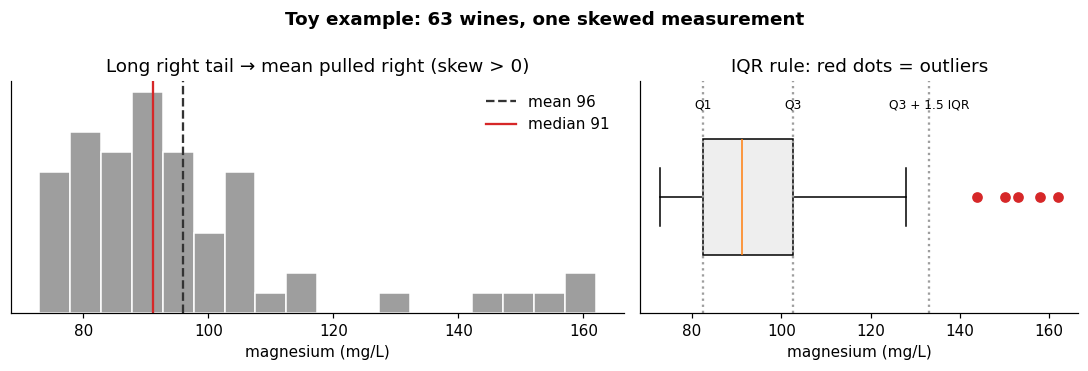

In [ ]:
q1, q3 = wine.quantile(0.25), wine.quantile(0.75)
iqr = q3 - q1
health = pd.DataFrame({'min': wine.min(), 'max': wine.max(), 'std': wine.std(),
                       'skewness': wine.apply(lambda c: skew(c)),
                       'IQR outliers': ((wine < q1 - 1.5 * iqr) | (wine > q3 + 1.5 * iqr)).sum()})

In [ ]:
display(health.round(2).sort_values('std', ascending=False))

# [4/12] EDA

**What I'm trying to do** → look at every distribution and at the correlations, to see which measurements carry the same information.

In [ ]:
fig, axes = plt.subplots(3, 5, figsize=(22, 11))
for ax, col in zip(axes.ravel(), FEATURES):
    sns.histplot(wine[col], bins=20, kde=True, color='grey', ax=ax)
    ax.set_title(f'{col}  (skew {skew(wine[col]):.2f})')
    ax.set_xlabel('')
for ax in axes.ravel()[len(FEATURES):]:
    ax.axis('off')
fig.suptitle('Distribution of every measurement', fontweight='bold')
fig.tight_layout()
save(fig, '01_distributions')
plt.show()

In [ ]:
corr = wine.corr(method='spearman')
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, cmap='Greys', annot=True, fmt='.2f', annot_kws={'size': 8}, vmin=-1, vmax=1, ax=ax)
ax.set_title('Spearman correlation between measurements')
save(fig, '02_correlation')
plt.show()

In [ ]:
pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().rename('rho').reset_index()
         .assign(abs_rho=lambda d: d['rho'].abs()).sort_values('abs_rho', ascending=False).head(6))
display(pairs.drop(columns='abs_rho').round(3))

**Question:** Which measurements tell the same story?

**Answer:** The phenol family: total phenols and flavanoids (ρ 0.88), flavanoids and OD280 (0.74), flavanoids and proanthocyanins (0.73). That is one "body" signal measured four ways. Alcohol rises with colour intensity (0.64).

**Spearman correlation in one line** → rank the wines on both measurements, then check how well the two rankings agree.

$$\rho_s = 1 - \frac{6\sum d_i^2}{n(n^2 - 1)}$$
- $d_i$ → difference between wine $i$'s two ranks
- $|\rho_s| > 0.7$ → largely the same information
- In short → only the order counts, so a curved relation or one extreme wine does not fool it

**How, in 3 steps**
1. Replace each value by its rank (1 = smallest)
2. For every wine, take the gap between its two ranks
3. Small gaps everywhere → ρ near 1; ranks in opposite order → ρ near −1

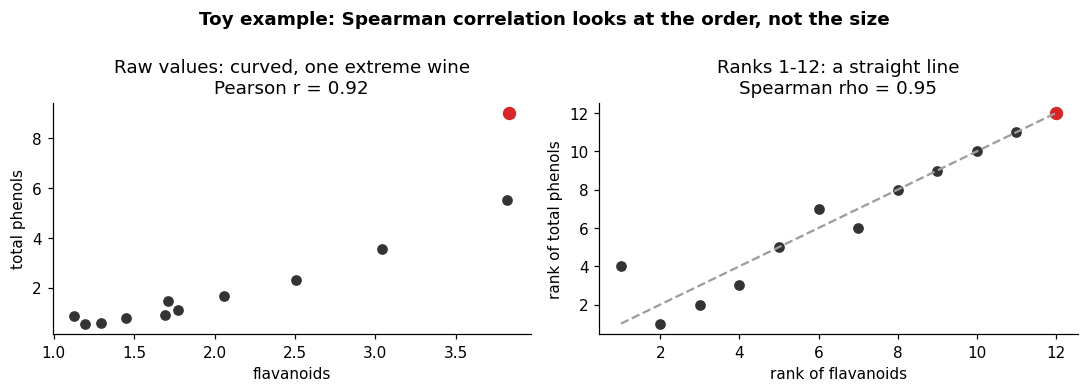

# [5/12] Scaling

**Aim** → cluster the raw numbers and the transformed numbers, and show that raw distances are decided by one measurement.

**Question:** What goes wrong if I cluster the raw numbers?

**Answer:** Raw clusters are just proline clusters.
- k-means on the raw numbers gives exactly the same groups as k-means on proline alone (ARI 1.00)
- after Yeo-Johnson the agreement drops to 0.36: every measurement has a say, and the mean |skewness| falls from 0.43 to 0.04

**Euclidean distance in one line** → the straight-line distance between two wines, adding up the squared gaps on every measurement.

$$d(a, b) = \sqrt{\sum_{j=1}^{13} (x_{aj} - x_{bj})^2}$$
- In short → a gap of 300 mg/L proline beats a gap of 0.5 in hue, just because of the units

**Yeo-Johnson in one line** → reshape each measurement so it looks roughly bell-shaped, then give it mean 0 and spread 1.

**How, in 3 steps**
1. For each measurement, try a family of power curves (square root, log, …) and keep the one that makes it most bell-shaped
2. Apply it (it also works for zeros and negatives, unlike a plain log)
3. Standardise: subtract the mean, divide by the spread

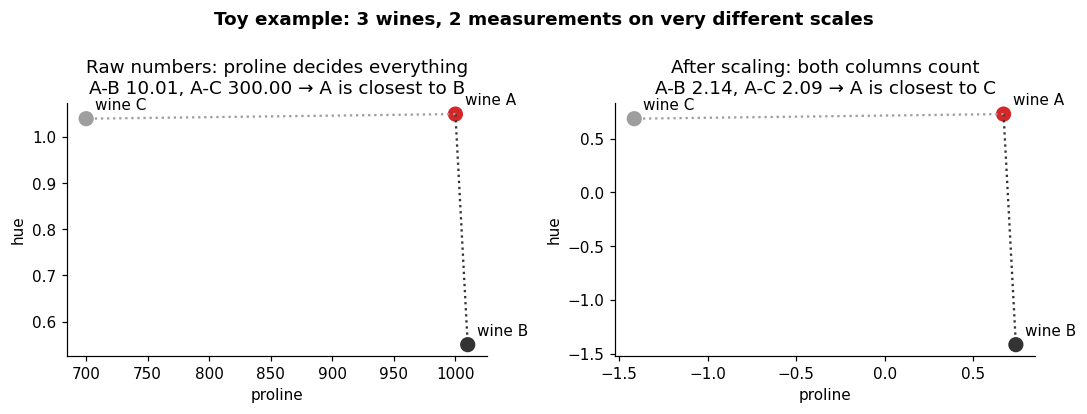

In [ ]:
transformer = make_transform()
X = transformer.fit_transform(wine)
X_std = StandardScaler().fit_transform(wine)

km_raw = KMeans(3, n_init=20, random_state=SEED).fit_predict(wine)
km_proline = KMeans(3, n_init=20, random_state=SEED).fit_predict(wine[['Proline']])
km_scaled = KMeans(3, n_init=20, random_state=SEED).fit_predict(X)
share = (wine['Proline'].var() / wine.var().sum())
scaling = pd.DataFrame({
    'raw numbers': {'agreement with "proline only" (ARI)': adjusted_rand_score(km_proline, km_raw)},
    f'{TRANSFORM}': {'agreement with "proline only" (ARI)': adjusted_rand_score(km_proline, km_scaled)}})
skew_after = pd.Series(skew(X), index=FEATURES)

In [ ]:
show_block('Outputs', {'proline share of total variance (raw)': f'{share:.1%}',
                       'mean |skewness| before': f'{health["skewness"].abs().mean():.2f}',
                       f'mean |skewness| after {TRANSFORM}': f'{skew_after.abs().mean():.2f}'})
display(scaling.round(3))

# [6/12] PCA: a map of the wines

**Aim** → squeeze 13 measurements into a few directions, to get a 2-D map and to see which measurements spread the wines most.

**Question:** How many directions are really needed to describe the wines?

**Answer:** Five for 80% of the variance, two for a useful map (56%).
- PC1 = the phenol family (flavanoids, total phenols, OD280)
- PC2 = colour intensity, alcohol and proline

**PCA in one line** → find the direction in which the wines differ most, then the next one at a right angle, and so on.

$$\text{explained variance of PC}_k = \frac{\lambda_k}{\sum_{j} \lambda_j}$$
- $\lambda_k$ → spread along direction $k$; loadings → how much each measurement points along it
- In short → turn the cloud of wines until you see it from its widest side

**How, in 3 steps**
1. Start from the transformed measurements (all on the same scale)
2. Find PC1 = the line with the most spread; PC2 = the most spread left, at a right angle to PC1
3. Each wine gets new coordinates on PC1, PC2 …; keep the first few

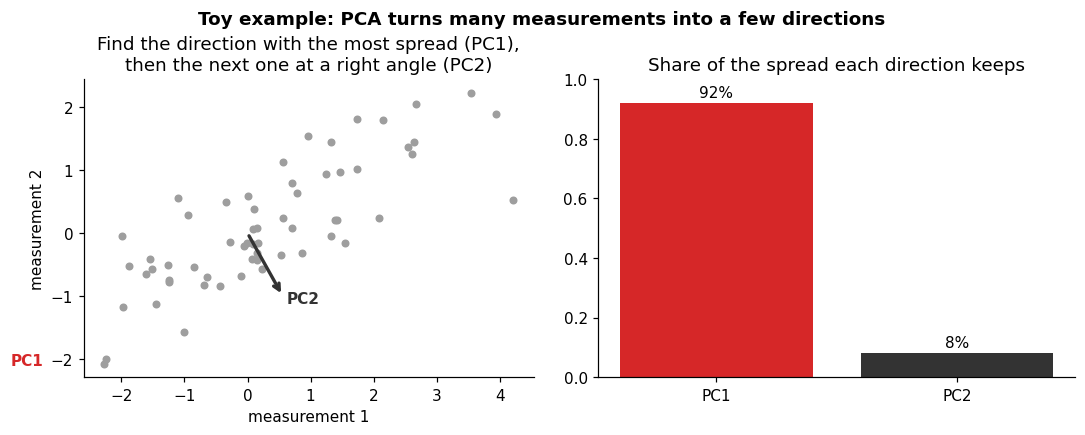

In [ ]:
pca = PCA(random_state=SEED).fit(X)
P = pca.transform(X)
explained = pd.Series(pca.explained_variance_ratio_, index=[f'PC{i + 1}' for i in range(len(FEATURES))])
loadings = pd.DataFrame(pca.components_[:2].T, index=FEATURES, columns=['PC1', 'PC2'])

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(22, 6))
axes[0].bar(explained.index, explained.values, color='grey')
axes[0].plot(explained.index, explained.cumsum().values, color='black', marker='o', label='cumulative')
axes[0].set(title='Explained variance', ylim=(0, 1.05))
axes[0].legend()
axes[0].tick_params(axis='x', rotation=90)
axes[1].scatter(P[:, 0], P[:, 1], s=25, color='black', alpha=0.7)
axes[1].set(title='Wines on the first two components', xlabel=f'PC1 ({explained.iloc[0]:.0%})', ylabel=f'PC2 ({explained.iloc[1]:.0%})')
order = loadings['PC1'].abs().sort_values().index
axes[2].barh(order, loadings.loc[order, 'PC1'], color='black', label='PC1')
axes[2].barh(order, loadings.loc[order, 'PC2'], color='grey', alpha=0.6, label='PC2')
axes[2].set(title='Loadings')
axes[2].legend()
fig.tight_layout()
save(fig, '03_pca')
plt.show()

In [ ]:
show_block('Outputs', {'PC1 + PC2': f'{explained.iloc[:2].sum():.1%}',
                       'components for 80 %': int((explained.cumsum() < 0.8).sum() + 1),
                       'top PC1 measurements': ', '.join(loadings['PC1'].abs().sort_values(ascending=False).index[:3]),
                       'top PC2 measurements': ', '.join(loadings['PC2'].abs().sort_values(ascending=False).index[:3])})

# [7/12] How many groups?

**What I'm trying to do** → score k = 2 … `K_MAX` with four rules and pick the k they agree on.

**Question:** How many natural wine groups are there?

**Answer:** Three. Silhouette (0.30), Calinski-Harabasz (73), Davies-Bouldin (1.36) and the mixture's BIC all pick k = 3. A silhouette of 0.30 means the groups touch rather than sit far apart.

**Silhouette in one line** → for every wine, compare how close it is to its own group with how close it is to the next group.

$$s(i) = \frac{b(i) - a(i)}{\max\{a(i), b(i)\}}$$
- $a(i)$ → mean distance to its own group; $b(i)$ → mean distance to the nearest other group
- $s$ near 1 → well placed; near 0 → on a border; below 0 → probably in the wrong group
- In short → good groups are tight inside and far from each other

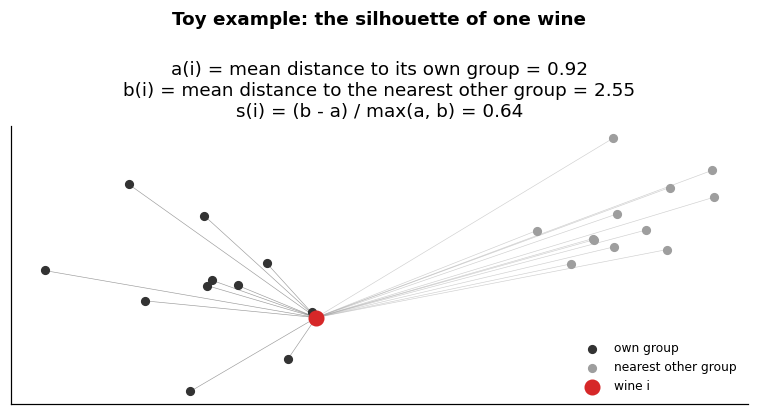

**The other three rules in one line each**
- **Elbow** → the total distance to the group centres (inertia) always falls with more groups; look for where it stops falling fast
- **Calinski-Harabasz** → spread between groups ÷ spread inside groups; higher is better
- **Davies-Bouldin** → how much each group overlaps its most similar group; lower is better
- **BIC** → how well a Gaussian mixture fits, with a penalty for extra groups; lower is better

In [ ]:
rows = []
for k in range(2, K_MAX + 1):
    km = KMeans(k, n_init=20, random_state=SEED).fit(X)
    gm = GaussianMixture(k, covariance_type='diag', n_init=5, random_state=SEED).fit(X)
    rows.append({'k': k, 'inertia': km.inertia_, **internal_scores(X, km.labels_), 'GMM BIC': gm.bic(X)})
k_scores = pd.DataFrame(rows).set_index('k')
K = K_FINAL or int(k_scores['silhouette'].idxmax())

In [ ]:
fig, axes = plt.subplots(1, 5, figsize=(26, 4.5))
for ax, col in zip(axes, k_scores.columns):
    ax.plot(k_scores.index, k_scores[col], color='black', marker='o')
    ax.axvline(K, color='grey', linestyle='--')
    ax.set(title=col, xlabel='k')
fig.suptitle(f'Choosing the number of groups (dashed line: k = {K})', fontweight='bold')
fig.tight_layout()
save(fig, '04_choose_k')
plt.show()

In [ ]:
display(k_scores.round(3))
show_block('Outputs', {'k by silhouette': int(k_scores['silhouette'].idxmax()),
                       'k by Calinski-Harabasz': int(k_scores['Calinski-Harabasz'].idxmax()),
                       'k by Davies-Bouldin': int(k_scores['Davies-Bouldin'].idxmin()),
                       'k by GMM BIC': int(k_scores['GMM BIC'].idxmin()), 'k used': K})

# [8/12] Four families of clustering

**Aim** → run one model from each family with k = `K` and compare how well each separates the wines.

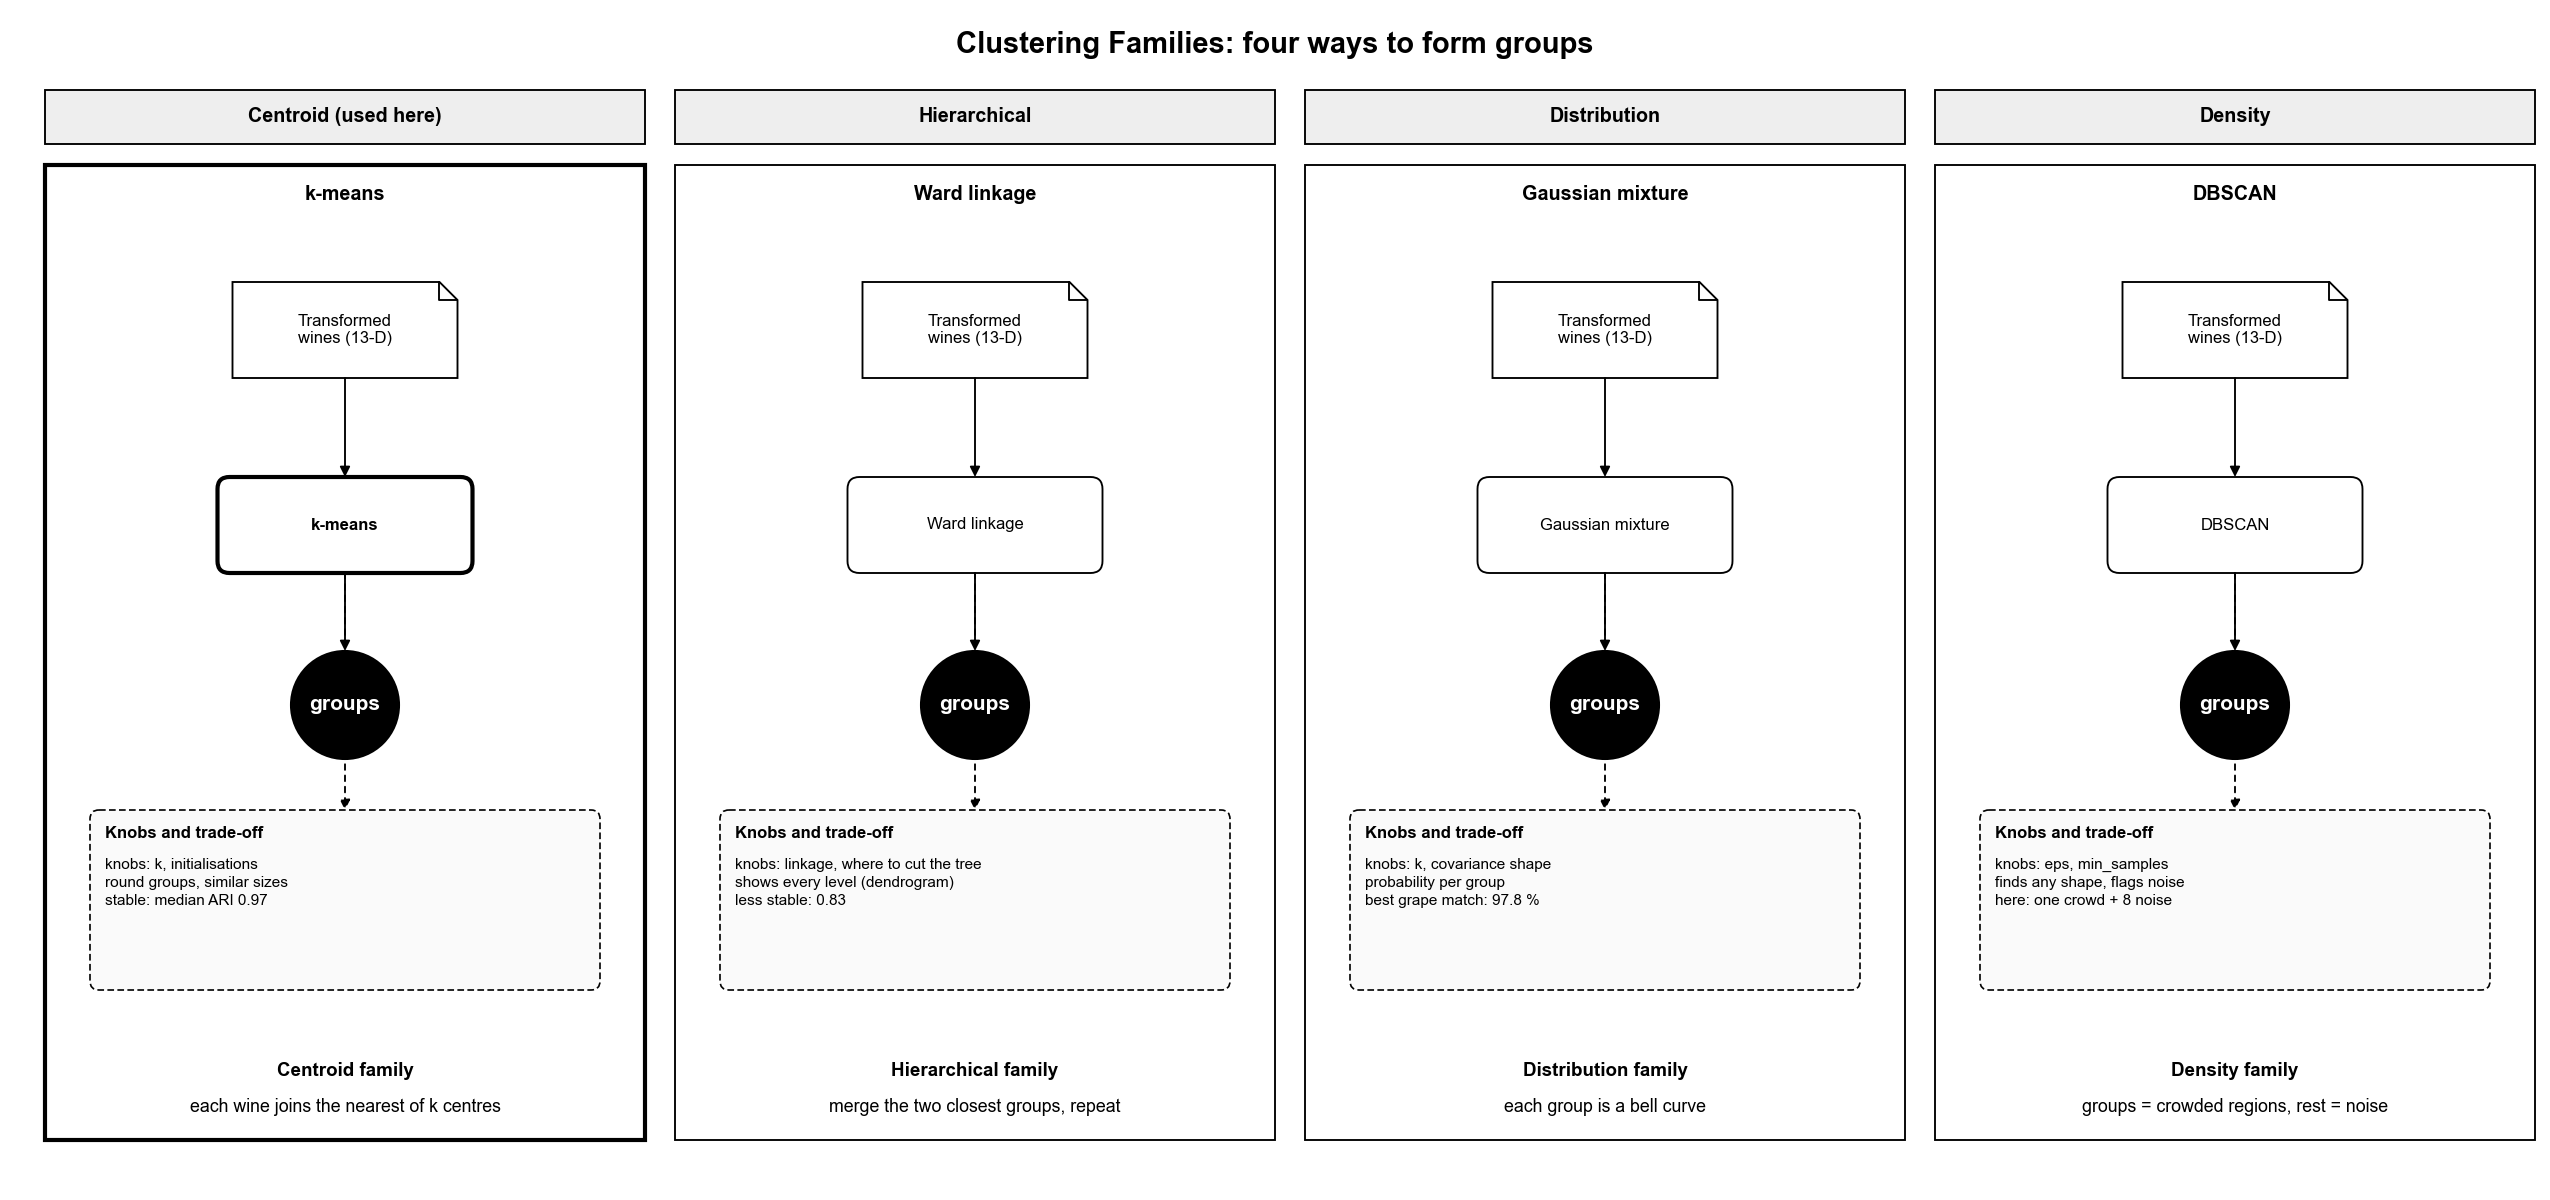

**Question:** Which family fits these wines best?

**Answer:** The three model-based families tie; density fails.
- silhouette: k-means 0.301, Gaussian mixture 0.297, Ward 0.290
- DBSCAN finds one crowd and 8 noise wines: in 13 dimensions there are no empty gaps to cut along

**k-means in one line** → every wine joins the nearest of k centres, and every centre moves to the middle of its wines, until nothing changes.

**How, in 4 steps**
1. Drop k centres (here k = 3)
2. Each wine joins its nearest centre
3. Each centre moves to the average of its wines
4. Repeat 2-3 until no wine changes group; run it many times from different starts and keep the tightest result

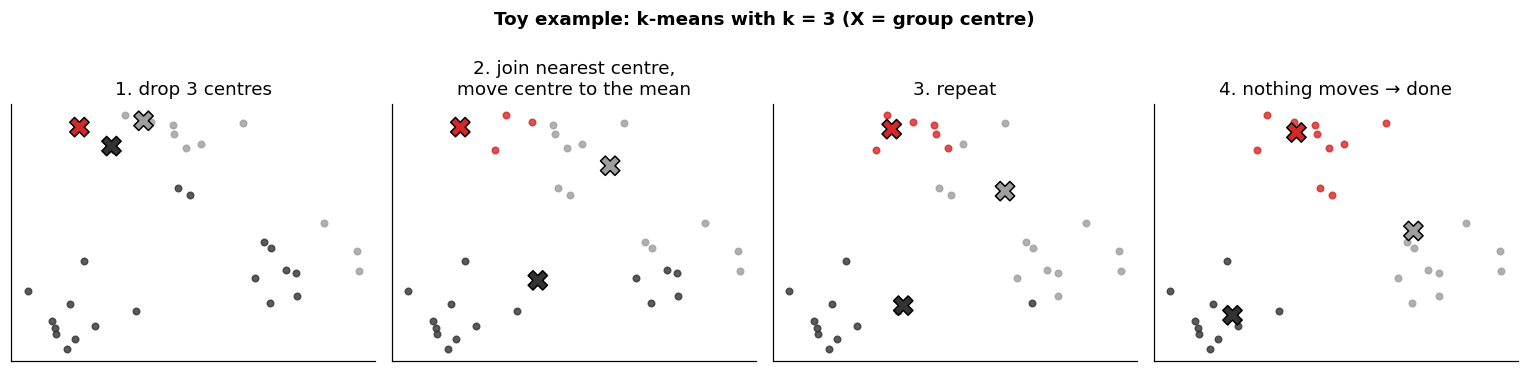

**Ward hierarchical in one line** → start with every wine alone and keep merging the two groups whose merge adds the least spread.

**How, in 3 steps**
1. Each wine is its own group
2. Merge the pair of groups that grows the within-group spread the least; repeat until one group is left
3. Read the tree (dendrogram) and cut it at the height that gives k groups

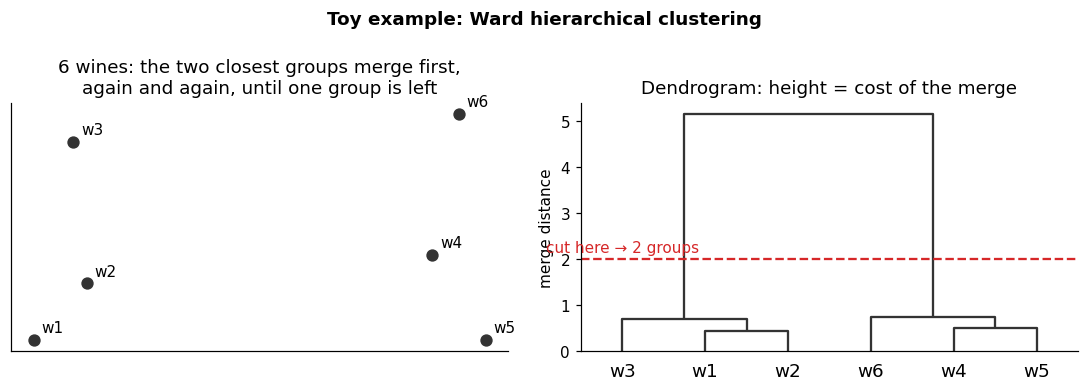

**Gaussian mixture in one line** → every group is a bell curve, and every wine gets a probability of belonging to each one.

**How, in 3 steps**
1. Start with k bell curves (a centre and a spread per measurement)
2. For each wine, compute how likely it is under each curve → probabilities that add up to 1
3. Move and reshape every curve to fit the wines it is responsible for; repeat until it settles

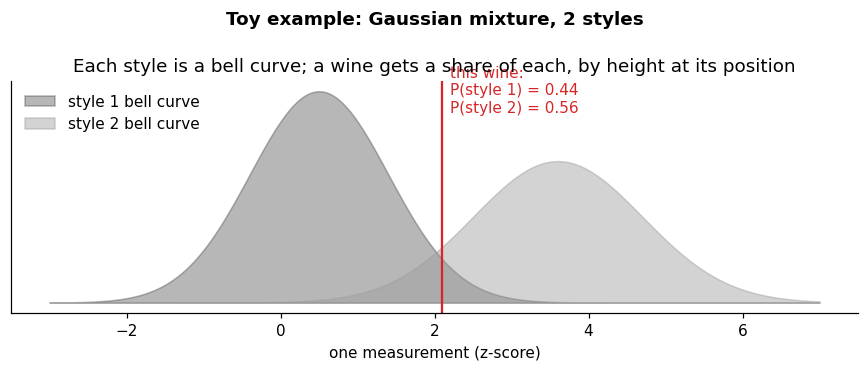

**DBSCAN in one line** → a group is a chain of crowded points; a wine alone in empty space is noise.

**How, in 3 steps**
1. A wine with at least `DBSCAN_MIN_SAMPLES` neighbours within distance eps is a **core** wine
2. Core wines that reach each other form one group; wines next to a core wine join it as **border**
3. Everything else is **noise**; eps comes from the sorted "distance to the 5th neighbour" curve (90th percentile)

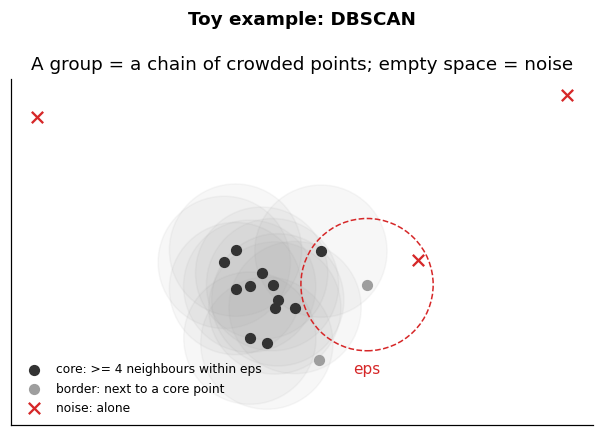

- In short → nearest captain (k-means), best friends merge (Ward), most likely club (mixture), who stands in a crowd (DBSCAN)

In [ ]:
eps_k = np.sort(NearestNeighbors(n_neighbors=DBSCAN_MIN_SAMPLES).fit(X).kneighbors(X)[0][:, -1])
DBSCAN_EPS = float(np.quantile(eps_k, 0.90))

models = {
    'k-means': KMeans(K, n_init=50, random_state=SEED),
    'Ward hierarchical': AgglomerativeClustering(K, linkage='ward'),
    'Gaussian mixture': GaussianMixture(K, covariance_type='diag', n_init=10, random_state=SEED),
    'DBSCAN': DBSCAN(eps=DBSCAN_EPS, min_samples=DBSCAN_MIN_SAMPLES),
}
labels = {name: m.fit_predict(X) for name, m in models.items()}
family = pd.DataFrame({name: {'groups': len(set(l[l >= 0])), 'noise wines': int((l < 0).sum()), **internal_scores(X, l)}
                       for name, l in labels.items()}).T

In [ ]:
display(family.round(3))

In [ ]:
tsne = TSNE(2, perplexity=30, random_state=SEED).fit_transform(X)
fig, axes = plt.subplots(2, 4, figsize=(24, 11))
for col, (name, lab) in enumerate(labels.items()):
    for row, emb in enumerate([P[:, :2], tsne]):
        ax = axes[row, col]
        for g in sorted(set(lab)):
            m = lab == g
            ax.scatter(emb[m, 0], emb[m, 1], s=28, color='white' if g < 0 else GREYS[g % len(GREYS)],
                       edgecolor='black', linewidth=0.5, label='noise' if g < 0 else f'group {g}')
        ax.set_title(f'{name} · {"PCA" if row == 0 else "t-SNE"}')
        ax.legend(fontsize=8)
fig.suptitle('The same wines, grouped by four families (top: PCA map, bottom: t-SNE map)', fontweight='bold')
fig.tight_layout()
save(fig, '05_families')
plt.show()

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(22, 5))
dendrogram(linkage(X, 'ward'), ax=axes[0], color_threshold=0, above_threshold_color='black', no_labels=True)
axes[0].set(title='Ward dendrogram: cutting at the largest vertical gap gives the groups', ylabel='merge distance')
axes[1].plot(eps_k, color='black')
axes[1].axhline(DBSCAN_EPS, color='grey', linestyle='--', label=f'eps = {DBSCAN_EPS:.2f} (90th percentile)')
axes[1].set(title=f'DBSCAN: distance to the {DBSCAN_MIN_SAMPLES}th neighbour, sorted', xlabel='wines', ylabel='distance')
axes[1].legend()
fig.tight_layout()
save(fig, '06_dendrogram_dbscan')
plt.show()

# [9/12] Stability

**Aim** → re-fit every family on bootstrap resamples. A real grouping comes back almost unchanged.

**Question:** Would the groups survive a slightly different set of wines?

**Answer:** k-means is the most stable (median ARI 0.97 over 100 resamples), then the Gaussian mixture (0.91) and Ward (0.83). DBSCAN never finds two groups, so I use k-means for the profiles.

**Bootstrap in one line** → draw 178 wines with replacement (some twice, some not at all), cluster again, and see whether the same groups come back.

**How, in 3 steps**
1. Draw a resample, fit the model on it
2. Give every one of the 178 wines the nearest centre of the new groups
3. Compare with the full-data groups using ARI; repeat `N_BOOT` times

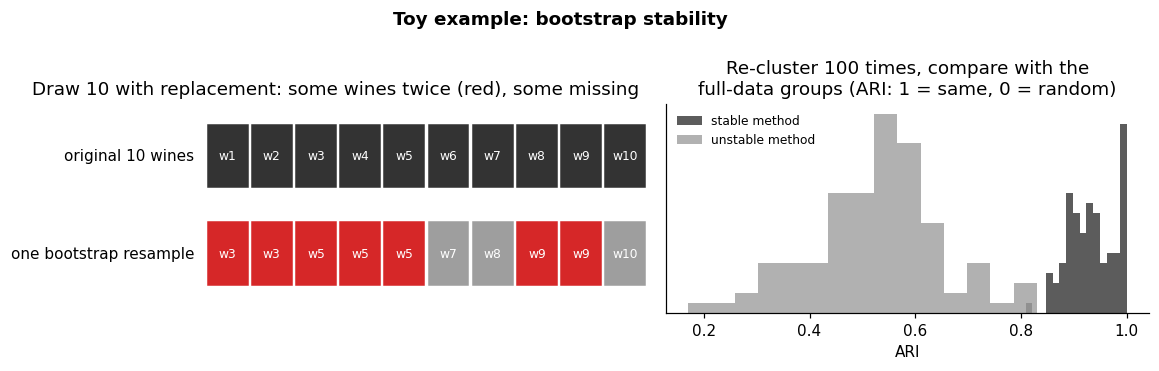

**ARI in one line** → the share of wine pairs two groupings agree on (same group / different group), corrected so that random labels score 0.

$$\text{ARI} = \frac{\text{RI} - \mathbb{E}[\text{RI}]}{\max(\text{RI}) - \mathbb{E}[\text{RI}]}$$
- 1 → identical groupings; 0 → no better than random; the group names do not matter
- In short → a second panel of tasters sorts the same wines: do they put the same pairs together?

In [ ]:
def nearest_centre(X_fit, lab_fit, X_all):
    groups = sorted(set(lab_fit[lab_fit >= 0]))
    centres = np.stack([X_fit[lab_fit == g].mean(axis=0) for g in groups])
    return np.array(groups)[np.argmin(((X_all[:, None, :] - centres[None]) ** 2).sum(axis=2), axis=1)]


rng = np.random.default_rng(SEED)
stability = {name: [] for name in models}
for _ in range(N_BOOT):
    idx = rng.integers(0, len(X), len(X))
    for name, model in models.items():
        lab = model.fit_predict(X[idx])
        if len(set(lab[lab >= 0])) < 2:
            stability[name].append(0.0)
            continue
        stability[name].append(adjusted_rand_score(labels[name], nearest_centre(X[idx], lab, X)))
stability = pd.DataFrame(stability)

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.boxplot(data=stability, color='lightgrey', ax=ax)
ax.set(title=f'Stability over {N_BOOT} bootstrap resamples (ARI with the full-data grouping)', ylabel='ARI', ylim=(-0.05, 1.05))
save(fig, '07_stability')
plt.show()
display(stability.describe().T[['mean', '25%', '50%', '75%']].round(3))

# [10/12] What makes each group different?

**What I'm trying to do** → describe the chosen groups in the original units, and give each one a name a wine seller could put on a shelf.

In [ ]:
best_name = family.drop(index='DBSCAN')['silhouette'].idxmax()
groups = labels[best_name]
z = pd.DataFrame(StandardScaler().fit_transform(wine), columns=FEATURES)
centres_z = z.groupby(groups).mean()


def style_name(row):
    top = row.abs().sort_values(ascending=False).index[:2]
    return ' · '.join(f'{"high" if row[c] > 0 else "low"} {c.lower().replace("_", " ")}' for c in top)


STYLE = {g: f'Style {chr(65 + i)}: {style_name(centres_z.loc[g])}' for i, g in enumerate(centres_z.index)}
profile = wine.groupby(groups).mean().T.round(2)
profile.columns = [STYLE[g].split(':')[0] for g in profile.columns]
profile['spread (std)'] = wine.std().round(2)

In [ ]:
show_block('Outputs', {'model used': best_name, **{STYLE[g]: f'{(groups == g).sum()} wines' for g in sorted(STYLE)}})
display(profile)

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(22, 6), gridspec_kw={'width_ratios': [1.3, 1]})
sns.heatmap(centres_z.T, cmap='Greys', center=0, annot=True, fmt='.1f', ax=axes[0],
            xticklabels=[STYLE[g].split(':')[0] for g in centres_z.index])
axes[0].set_title('Group centres in standard deviations from the average wine')
key = centres_z.abs().max().sort_values(ascending=False).index[:4]
long = z[key].assign(style=[STYLE[g].split(':')[0] for g in groups]).melt(id_vars='style')
sns.violinplot(data=long, x='variable', y='value', hue='style', hue_order=sorted(long['style'].unique()),
               palette='Greys', ax=axes[1], cut=0)
axes[1].set(title='The four measurements that separate the groups most', xlabel='', ylabel='z-score')
fig.tight_layout()
save(fig, '08_profiles')
plt.show()

**Question:** How would a wine seller describe each group?

**Answer:** Three easy-to-explain styles.
- **A, light** (64 wines) → 12.3% alcohol, pale colour (3.0), little proline (505)
- **B, deep and low in phenols** (52) → dark colour (7.2), brownish hue (0.70), low flavanoids (0.82), more malic acid
- **C, full-bodied** (62) → 13.7% alcohol, rich in phenols (flavanoids 3.0), very high proline (1,100)

**Z-score profile in one line** → express each group centre in "standard deviations from the average wine", then name the group after its two most extreme measurements.

**How, in 3 steps**
1. Standardise every measurement (mean 0, spread 1)
2. Average the wines of each group → one bar per measurement
3. The two longest bars name the group; flavanoids, total phenols and OD280 mean body and ageing potential, colour intensity and hue mean how deep and how brown-red the wine looks, proline goes with fuller, riper wines

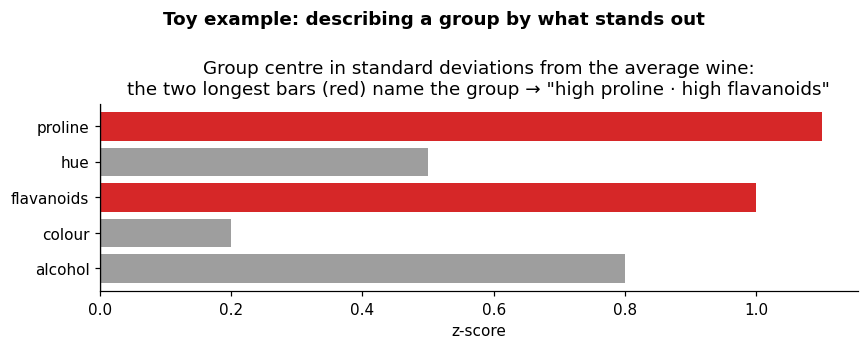

- In short → describe three friends by what stands out most, not by every detail

# [11/12] The answer key: grape varieties

**Aim** → only now open the hidden labels (the UCI wine data has the variety of every wine) and count how many wines land with their own variety.

**Question:** Did the unsupervised groups rediscover the grape varieties?

**Answer:** Almost perfectly.
- k-means: 96.1% of wines land with their own variety (ARI 0.88); the Gaussian mixture: 97.8% (ARI 0.93)
- only 7 wines of variety 1 are misplaced (4 in Style B, 3 in Style C)
- so the chemistry alone separates the three grapes

The labels come from `sklearn.datasets.load_wine`: the same 178 wines in the same order, never used before this section.

**Hungarian matching in one line** → pair each group with one variety so that the total number of wines in agreement is as large as possible.

**How, in 3 steps**
1. Count wines in a table: groups × varieties
2. Pick one cell per row and per column with the largest total (the Hungarian algorithm does this without trying every pairing)
3. Accuracy = matched wines ÷ all wines

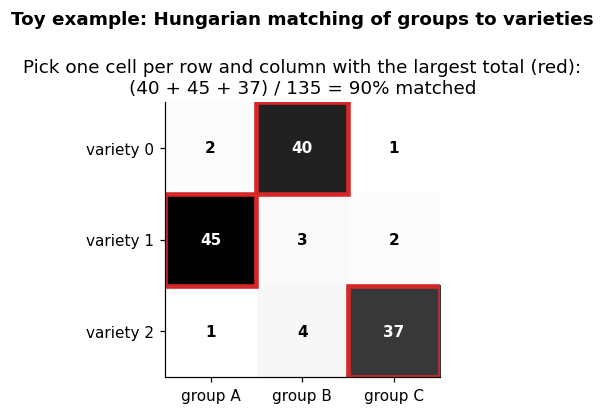

- In short → sort unlabelled bottles by taste, then read the labels and count the hits

In [ ]:
answer = load_wine()
assert np.allclose(answer.data, wine.to_numpy()), '(!) rows differ from the UCI wine data'
variety = np.array([f'variety {i}' for i in answer.target])


def matched_accuracy(true, pred):
    t = pd.factorize(true)[0]
    cm = confusion_matrix(t, np.where(pred < 0, pred.max() + 1, pred))          # DBSCAN noise = its own column
    r, c = linear_sum_assignment(-cm)
    return cm[r, c].sum() / len(true)


key_check = pd.DataFrame({name: {'ARI with variety': adjusted_rand_score(variety, l),
                                 'wines in matched variety': matched_accuracy(variety, l)}
                          for name, l in labels.items()}).T
crosstab = pd.crosstab(pd.Series([STYLE[g].split(':')[0] for g in groups], name='group'), pd.Series(variety, name='variety'))

In [ ]:
display(key_check.round(3))
display(crosstab)

# [12/12] Using the groups

**Aim** → assign a new wine to a style with probabilities, suggest similar wines, and flag wines that fit no style. The same logic runs in the Gradio app.

**Question:** What can a shop do with the groups tomorrow?

**Answer:** Three small tools.
- wine 0 → Style C with probability 1.00; its 5 nearest wines are all Style C
- the 5 oddest wines include the maximum flavanoids (5.08) and the maximum colour intensity (13.0), worth a lab re-check
- the Gradio app does the same for any slider settings

**Nearest neighbours in one line** → transform the new wine the same way, then list the 5 known wines closest to it.

**Odd wines in one line** → the wines the Gaussian mixture finds least likely (lowest log-likelihood) fit no style well.

**How, in 3 steps**
1. **New wine** → apply the same Yeo-Johnson transform, then the mixture gives P(style) for each style
2. **Similar wines** → the 5 nearest wines in the transformed space ("if you liked this one …")
3. **Odd wines** → sort all wines by log-likelihood and look at the bottom 5

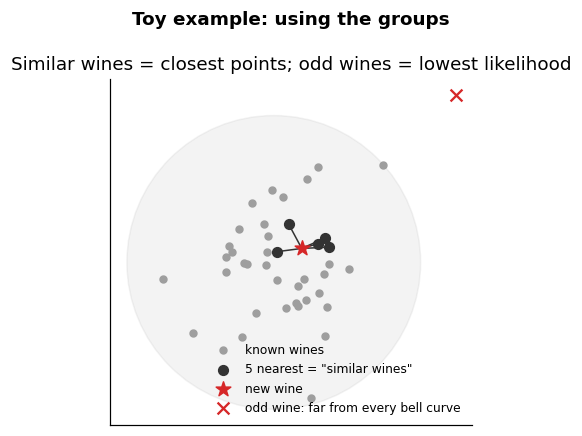

- In short → a sommelier who says "this is mostly style B, a bit like these five, and that one over there is unusual"

In [ ]:
gmm = GaussianMixture(K, covariance_type='diag', n_init=10, random_state=SEED).fit(X)
gmm_to_style = {}
for g in range(K):
    members = gmm.predict(X) == g
    gmm_to_style[g] = pd.Series(groups[members]).mode().iloc[0] if members.any() else g
nn = NearestNeighbors(n_neighbors=6).fit(X)


def describe_wine(values):
    x = transformer.transform(pd.DataFrame([values], columns=FEATURES))
    proba = pd.Series(gmm.predict_proba(x)[0], index=[STYLE[gmm_to_style[g]] for g in range(K)]).groupby(level=0).sum()
    dist, idx = nn.kneighbors(x)
    similar = wine.iloc[idx[0][:5]].assign(style=[STYLE[groups[i]].split(':')[0] for i in idx[0][:5]], distance=dist[0][:5].round(2))
    return proba.sort_values(ascending=False), similar


example = wine.iloc[0].to_dict()
proba, similar = describe_wine(example)
loglik = gmm.score_samples(X)
odd = wine.assign(style=[STYLE[g].split(':')[0] for g in groups], log_likelihood=loglik.round(1)).nsmallest(5, 'log_likelihood')

In [ ]:
show_block('Example: wine 0', {k: f'{v:.3f}' for k, v in proba.items()})
display(similar.round(2))
display(odd.round(2))

In [ ]:
"""Optional · Set LAUNCH_APP = True in the top cell to start the style finder (Kaggle prints a public link)."""
if LAUNCH_APP:
    import gradio as gr

    def app_fn(*values):
        p, sim = describe_wine(dict(zip(FEATURES, values)))
        return p.to_dict(), sim.round(2)

    sliders = [gr.Slider(float(wine[c].min()), float(wine[c].max()), value=float(wine[c].median()), label=c) for c in FEATURES]
    gr.Interface(app_fn, sliders, [gr.Label(label='Style'), gr.Dataframe(label='5 most similar wines')],
                 title='Wine style finder').launch(share=True)
else:
    print('Preview · app not started (LAUNCH_APP = False)')

**Summary**

- **Prepare** → I transform every measurement (Yeo-Johnson): raw distances are 99.8% proline
- **Groups** → k = 3 by four rules; k-means is the most stable (median ARI 0.97)
- **Styles** → light (A), deep and low in phenols (B), full-bodied (C)
- **Check** → 96-98% of wines match their grape variety without ever seeing it
- **Next** → price and taste-panel data, to turn styles into shelves and recommendations